# Food-101 EDA Notebook

**Owners:** Madhur Modi (Primary), Samuel Pradeep (Co-owner)

Exploratory Data Analysis for Food-101 dataset validation and quality checks.

In [5]:
import tensorflow as tf
import tensorflow_datasets as tfds
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load dataset info
ds, info = tfds.load('food101', with_info=True, as_supervised=True)
class_names = info.features['label'].names
num_classes = info.features['label'].num_classes

print(f'Classes: {num_classes}')
print(f'Train size: {info.splits["train"].num_examples}')
print(f'Validation size: {info.splits["validation"].num_examples}')

Classes: 101
Train size: 75750
Validation size: 25250


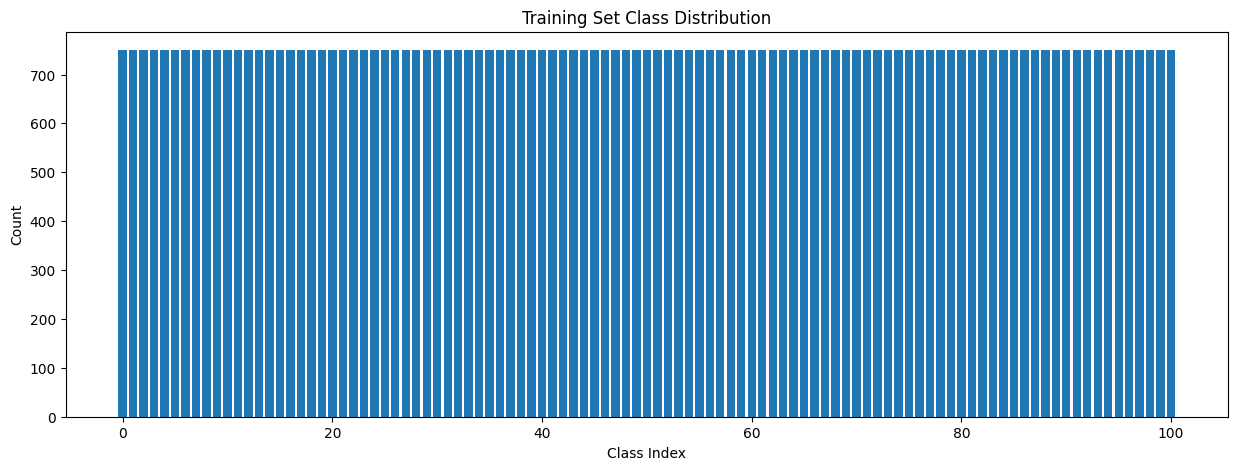

Min per class: 750
Max per class: 750
Mean per class: 750.0


In [6]:
# Class distribution
train_counts = []
for example in tfds.as_numpy(ds['train']):
    train_counts.append(example[1])

train_counts = np.array(train_counts)
unique, counts = np.unique(train_counts, return_counts=True)

plt.figure(figsize=(15, 5))
plt.bar(unique, counts)
plt.title('Training Set Class Distribution')
plt.xlabel('Class Index')
plt.ylabel('Count')
plt.show()

print(f'Min per class: {counts.min()}')
print(f'Max per class: {counts.max()}')
print(f'Mean per class: {counts.mean():.1f}')

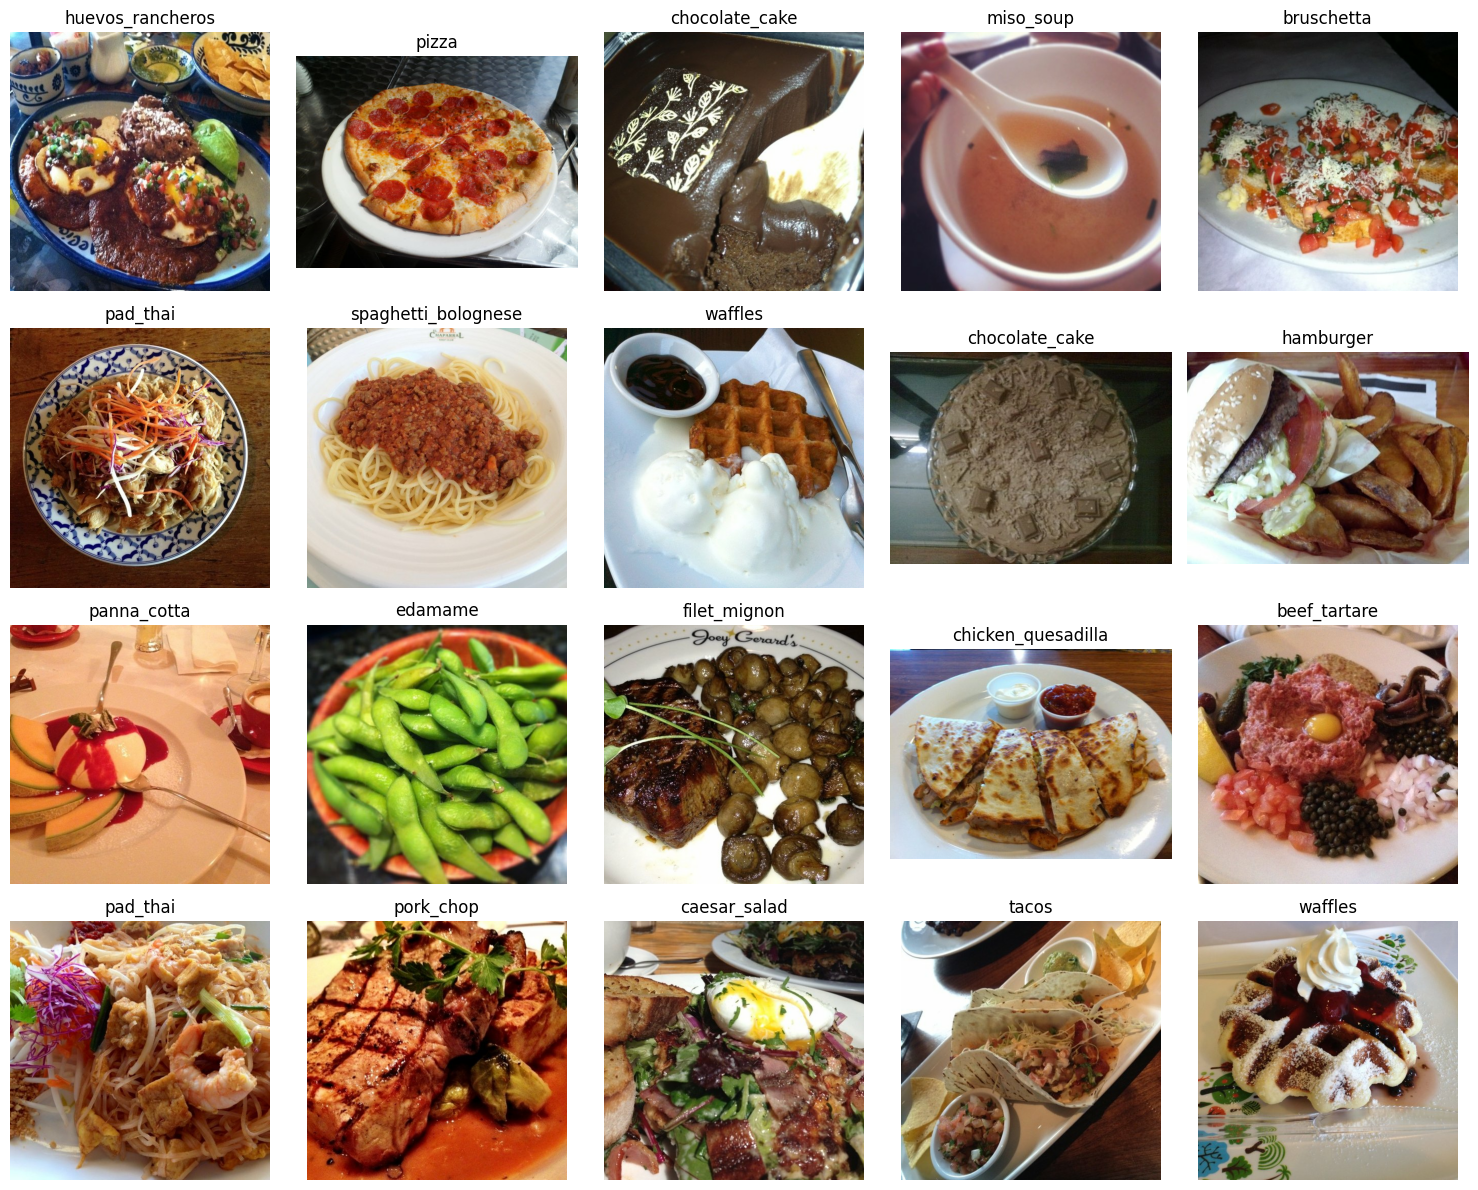

In [7]:
# Sample images visualization
fig, axes = plt.subplots(4, 5, figsize=(15, 12))
axes = axes.flatten()

for i, (image, label) in enumerate(ds['train'].take(20)):
    axes[i].imshow(image.numpy())
    axes[i].set_title(class_names[label.numpy()])
    axes[i].axis('off')

plt.tight_layout()
plt.show()

In [8]:
# Image shape analysis
shapes = []
for image, _ in tfds.as_numpy(ds['train']):
    shapes.append(image.shape)
    if len(shapes) >= 1000:
        break

shapes = np.array(shapes)
print(f'Shape range: {shapes.min(axis=0)} to {shapes.max(axis=0)}')
print(f'Median shape: {np.median(shapes, axis=0)}')

Shape range: [287 288   3] to [512 512   3]
Median shape: [512. 512.   3.]
